<a href="https://colab.research.google.com/github/sri-22-09/Exploratory-Data-Analysis-on-a-Cars-Dataset/blob/main/Cars_EDA_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [24]:
from google.colab import files
uploaded = files.upload()

Saving pre-owned cars-selected-columns.csv to pre-owned cars-selected-columns (1).csv


In [25]:
csv_file = next(iter(uploaded))
df = pd.read_csv(csv_file)

In [26]:
# Check missing values count across all columns
print("--- Missing Values Summary ---")
print(df.isnull().sum())
# Check and remove duplicate rows if any exist
duplicates=df.duplicated().sum()
print(f"\nNumber of duplicate rows found:{duplicates}")
if duplicates>0:
  df = df.drop_duplicates()
  print("Duplicate rows successfully removed!")


--- Missing Values Summary ---
brand                     1
model                     1
transmission              1
make_year                 1
reg_year               2086
fuel_type                 1
engine_capacity(CC)     118
km_driven                 1
ownership                 1
price                     0
dtype: int64

Number of duplicate rows found:1
Duplicate rows successfully removed!


In [27]:
df.head()

,brand,model,transmission,make_year,reg_year,fuel_type,engine_capacity(CC),km_driven,ownership,price
0,Mahindra,Thar LX D 4WD MT CONVERTIBLE,Manual,2020.0,01-01-2021,Diesel,2184.0,11003.0,1st owner,1231000
1,Hyundai,Verna 1.6 VTVT SX,Manual,2018.0,01-07-2018,Petrol,1591.0,66936.0,1st owner,786000
2,Tata,Harrier XT PLUS 2.0L KRYOTEC DARK EDITON,Manual,2022.0,01-08-2022,Diesel,1956.0,27990.0,1st owner,1489000
3,Honda,City 1.5L I-VTE V CVT,Automatic,2023.0,01-04-2023,Petrol,1498.0,5061.0,1st owner,1227000
4,Ford,Ecosport TITANIUM 1.5L DIESEL,Manual,2021.0,01-07-2021,Diesel,1498.0,23480.0,1st owner,887000


In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2805 entries, 0 to 2805
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   brand                2804 non-null   object 
 1   model                2804 non-null   object 
 2   transmission         2804 non-null   object 
 3   make_year            2804 non-null   float64
 4   reg_year             720 non-null    object 
 5   fuel_type            2804 non-null   object 
 6   engine_capacity(CC)  2687 non-null   float64
 7   km_driven            2804 non-null   float64
 8   ownership            2804 non-null   object 
 9   price                2805 non-null   int64  
dtypes: float64(3), int64(1), object(6)
memory usage: 305.6+ KB


In [29]:
df.dropna(subset=['brand'],inplace=True)

In [30]:
df['engine_capacity(CC)']=df['engine_capacity(CC)'].fillna(df['engine_capacity(CC)'].median())

In [31]:
# 1. Drop 'reg_year' if it has too many missing values
if "reg_year" in df.columns:
  df = df.drop(columns=["reg_year"])
# 2. Safety check: Fill any remaining missing 'brand' or 'engine_capacity(CC)'
if df["brand"].isnull().sum()>0:
  df["brand"] = df["brand"].fillna(df["brand"].mode()[0])
if df["engine_capacity(CC)"].isnull().sum() > 0:
  df["engine_capacity(CC)"]=df["engine_capacity(CC)"].fillna(df["engine_capacity(CC)"].median()
  )
# 3. Create a new feature: Car Age
if "make_year" in df.columns:
  df["car_age"]=2026-df["make_year"]

print("--- Data Cleaning Complete ---")
print(df[["make_year","car_age","price","km_driven"]].head())


--- Data Cleaning Complete ---
   make_year  car_age    price  km_driven
0     2020.0      6.0  1231000    11003.0
1     2018.0      8.0   786000    66936.0
2     2022.0      4.0  1489000    27990.0
3     2023.0      3.0  1227000     5061.0
4     2021.0      5.0   887000    23480.0


In [32]:
print('New Dataset Shape: ',df.shape)

New Dataset Shape:  (2804, 10)


In [33]:
print('Remaining Null Values: \n',df.isnull().sum())

Remaining Null Values: 
 brand                  0
model                  0
transmission           0
make_year              0
fuel_type              0
engine_capacity(CC)    0
km_driven              0
ownership              0
price                  0
car_age                0
dtype: int64


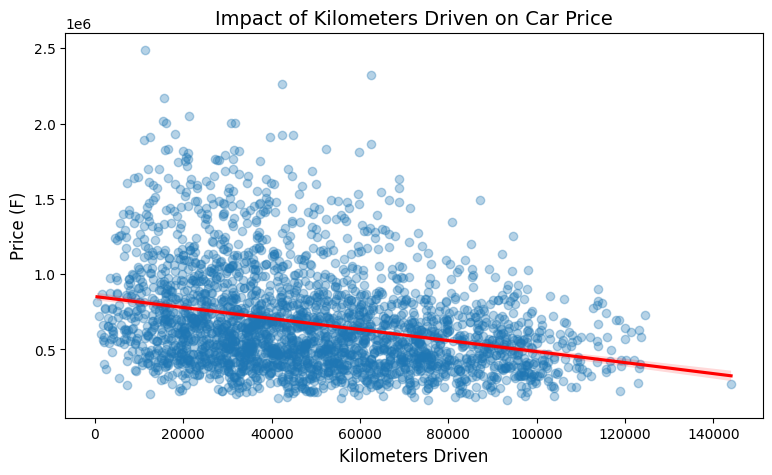

In [34]:
plt.figure(figsize=(9,5))
sns.regplot(
    x='km_driven',
    y='price',
    data=df,
    scatter_kws={'alpha':0.33},
    line_kws={'color':'red'},
)
plt.title('Impact of Kilometers Driven on Car Price',fontsize=14)
plt.xlabel('Kilometers Driven',fontsize=12)
plt.ylabel('Price (F)',fontsize=12)
plt.show()

In [35]:
plt.savefig("chart1_km_vs_price.png",bbox_inches="tight",dpi=300)
print("Saved Chart 1 successfully!")

Saved Chart 1 successfully!


<Figure size 640x480 with 0 Axes>

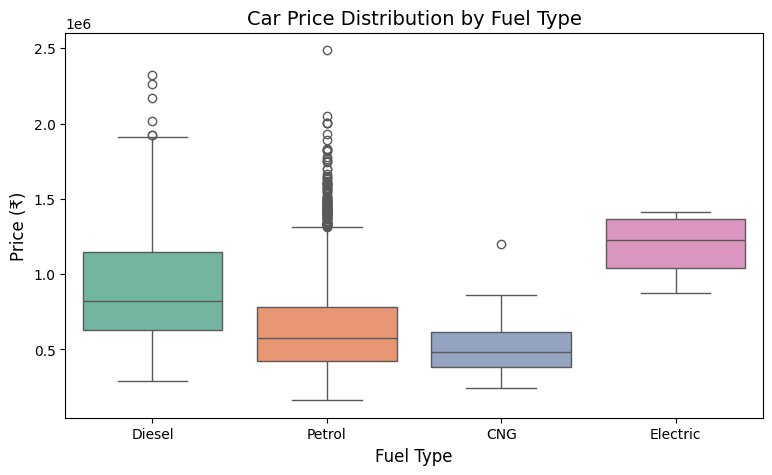

In [36]:
plt.figure(figsize=(9,5))
sns.boxplot(
    x='fuel_type',
    y='price',
    data=df,
    palette='Set2',
    hue='fuel_type'
)
plt.title('Car Price Distribution by Fuel Type',fontsize=14)
plt.xlabel('Fuel Type', fontsize=12)
plt.ylabel('Price (₹)', fontsize=12)
plt.show()


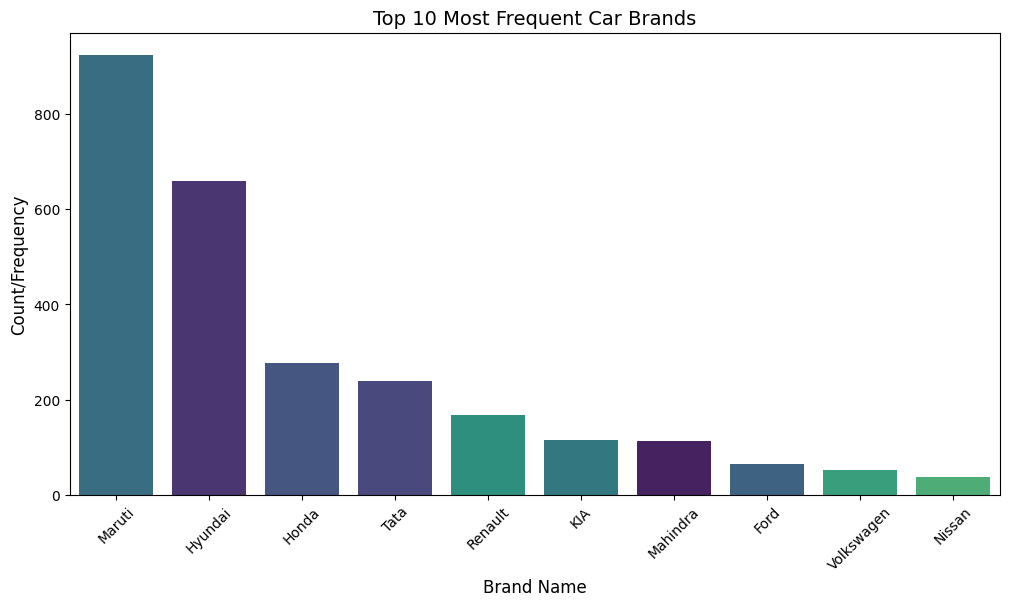

In [37]:
plt.figure (figsize=(12,6))
sns.countplot(
    x='brand',
    data=df,
    order=df['brand'].value_counts().index[:10],
    palette='viridis',
    hue='brand',
    legend=False,
)
plt.title('Top 10 Most Frequent Car Brands',fontsize=14)
plt.xlabel('Brand Name',fontsize=12)
plt.ylabel ('Count/Frequency',fontsize=12)
plt.xticks(rotation=45)
plt.show()

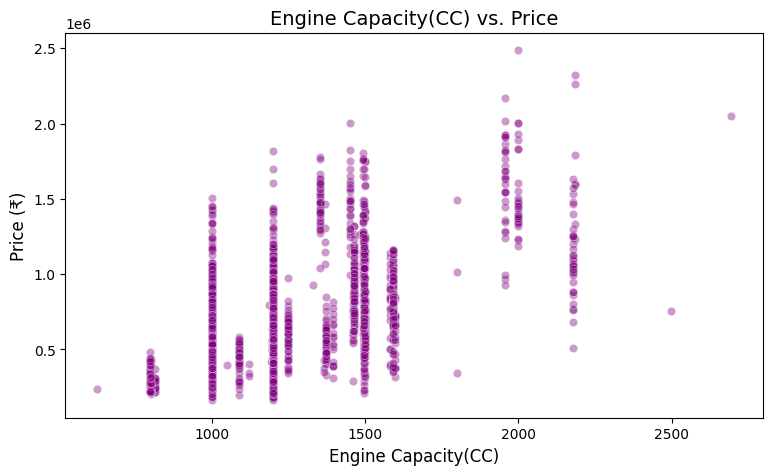

In [38]:
plt.figure(figsize=(9,5))
sns.scatterplot(
    x='engine_capacity(CC)',
    y='price',
    data=df,
    color='purple',
    alpha=0.4,
)
plt.title('Engine Capacity(CC) vs. Price',fontsize=14)
plt.xlabel('Engine Capacity(CC)',fontsize=12)
plt.ylabel('Price (₹)',fontsize=12)
plt.show()


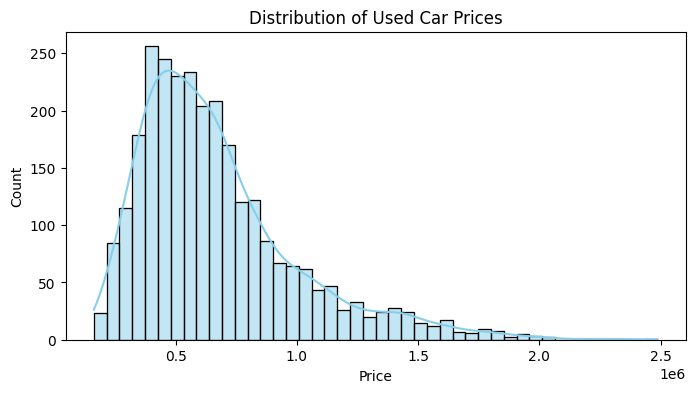

In [39]:
plt.figure(figsize=(8,4))
sns.histplot(df["price"],kde=True,color="skyblue")
plt.title("Distribution of Used Car Prices")
plt.xlabel("Price")
plt.ylabel("Count")
plt.savefig("chart2_price_distribution.png",bbox_inches="tight",dpi=300)
plt.show()

/tmp/ipykernel_1951/2157851157.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_brands.values,y=top_brands.index,palette="viridis")


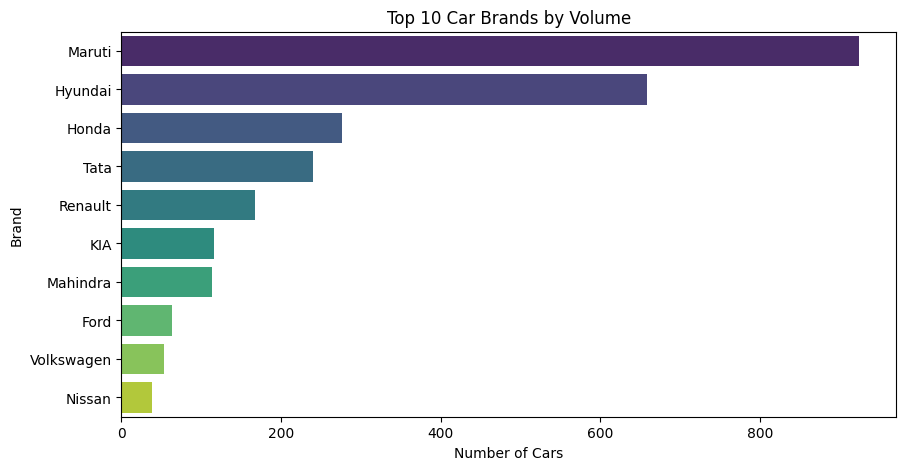

In [40]:
plt.figure(figsize=(10, 5))
top_brands=df["brand"].value_counts().head(10)
sns.barplot(x=top_brands.values,y=top_brands.index,palette="viridis")
plt.title("Top 10 Car Brands by Volume")
plt.xlabel("Number of Cars")
plt.ylabel("Brand")
plt.savefig("chart3_top_brands.png",bbox_inches="tight",dpi=300)
plt.show()


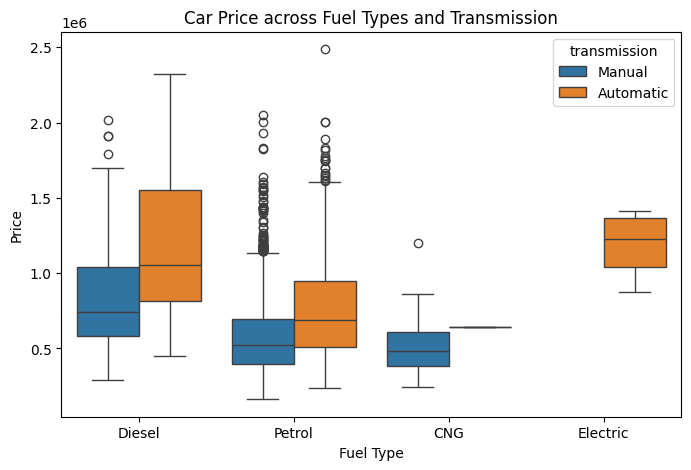

In [41]:
plt.figure(figsize=(8,5))
sns.boxplot(x="fuel_type",y="price",hue="transmission",data=df)
plt.title("Car Price across Fuel Types and Transmission")
plt.xlabel("Fuel Type")
plt.ylabel("Price")
plt.savefig("chart4_price_fuel_transmission.png",bbox_inches="tight",dpi=300)
plt.show()

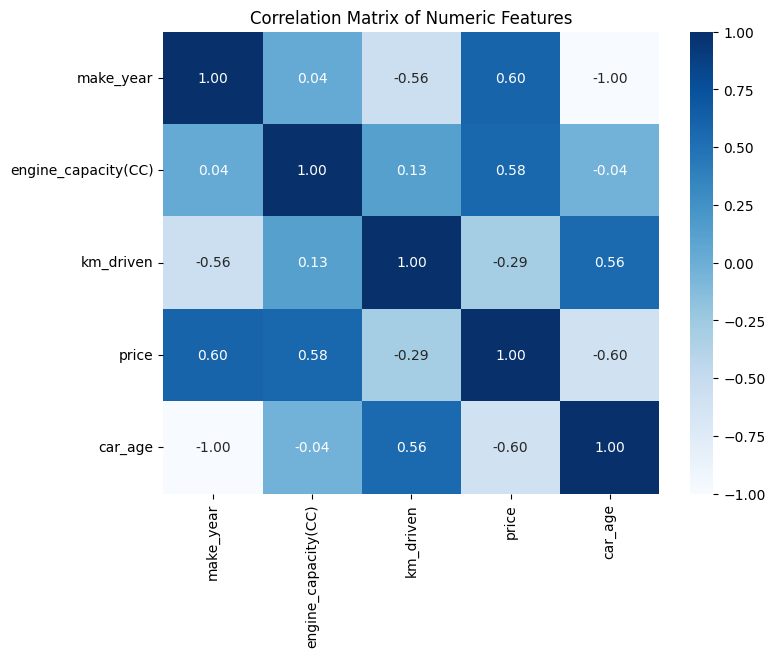

In [42]:
plt.figure(figsize=(8,6))
numeric_cols=df.select_dtypes(include=[np.number])
sns.heatmap(numeric_cols.corr(),annot=True,cmap="Blues",fmt=".2f")
plt.title("Correlation Matrix of Numeric Features")
plt.savefig("chart5_correlation_heatmap.png",bbox_inches="tight",dpi=300)
plt.show()


In [43]:
print("--- DATASET SUMMARY & FINDINGS ---")
print(f"Total Cars Analyzed: {len(df)}")
print(f"Average Car Price: ₹{df['price'].mean():,.2f}")
print(f"Median Car Price: ₹{df['price'].median():,.2f}")
print(f"Average Kilometers Driven: {df['km_driven'].mean():,.0f} km")
print(
    f"Most Common Fuel Type: {df['fuel_type'].mode()[0]} "
    f"({df['fuel_type'].value_counts().iloc[0]} cars)"
)
print(
    f"Most Common Brand: {df['brand'].mode()[0]} "
    f"({df['brand'].value_counts().iloc[0]} cars)"
)


--- DATASET SUMMARY & FINDINGS ---
Total Cars Analyzed: 2804
Average Car Price: ₹671,567.40
Median Car Price: ₹594,000.00
Average Kilometers Driven: 49,221 km
Most Common Fuel Type: Petrol (2372 cars)
Most Common Brand: Maruti (925 cars)
